<p class="lead">This unit is the course's first <em>predictive</em> model. Until now we have represented molecules (Units 2-5), curated and explored them (Units 6-8) and screened them with rules (Units 9-10). Here we finally ask a molecule to <strong>predict a number</strong>: how soluble is it, how potent is it. The tool is a method older than the field's name - the quantitative structure-activity relationship, or QSAR - and in its classical form it is nothing more exotic than the linear regression you already know, with molecular descriptors as the features. The work of this unit is therefore not the mathematics but the chemistry inside it: what the features mean, what a fitted coefficient says about a molecule, and the specific ways a chemical dataset makes an innocent-looking regression lie to you.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Recount the origin of QSAR - Hammett's electronic constants, Hansch's hydrophobic analysis, and the Free-Wilson additive model - and state the assumption they share.</li>
<li>Frame a QSAR as a supervised-learning pipeline: descriptors &rarr; split &rarr; fit &rarr; validate &rarr; interpret.</li>
<li>Derive the least-squares normal equations and solve a two-descriptor model by hand, then confirm it with NumPy and scikit-learn.</li>
<li>Fit a linear QSAR for aqueous solubility from RDKit descriptors and read every coefficient as a chemical statement.</li>
<li>Diagnose collinearity (correlation, variance-inflation factors) and recognise the coefficient instability it causes; know the standard remedies.</li>
<li>Demonstrate over-fitting as descriptors are added, and separate a model's fit from its predictivity.</li>
<li>Build a Free-Wilson group-contribution model and contrast it with a Hansch model.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it once linearly; then re-run each cell changing one thing at a time (a descriptor, the random seed, the regularisation strength) and watch what moves. Green <strong>chemistry boxes</strong> define each chemical term the first time it appears. The only library you must install in Google Colab is RDKit (<code>!pip install rdkit</code>); NumPy, pandas, matplotlib and scikit-learn are already there. Everything runs in seconds on the free tier - classical QSAR is deliberately light.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, Crippen, Lipinski, rdMolDescriptors
rdkit.RDLogger.DisableLog("rdApp.*")             # silence valence/parse chatter in this teaching notebook
import sklearn
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("RDKit", rdkit.__version__, "| scikit-learn", sklearn.__version__)
print("A molecule is about to predict a number.")

RDKit 2026.03.4 | scikit-learn 1.9.0
A molecule is about to predict a number.


## 1. From structure to property: the idea behind QSAR

The founding idea of QSAR is older than computers and even older than the structural theory of chemistry is comfortable with. In 1868 Crum-Brown and Fraser proposed that a compound's physiological action is a <em>function of its chemical constitution</em> - that if you change the structure a little, the activity changes in a related, in-principle-predictable way. Written in modern notation their claim is simply $\text{activity} = f(\text{structure})$, and the entire discipline of this course is the search for computable versions of that function $f$.

Two developments turned the slogan into arithmetic. First, in 1937 Louis Hammett showed that the effect of a chemical substituent on reaction rates and equilibria of benzene derivatives could be captured by a single number per substituent, the **electronic constant** $\sigma$, obeying a linear free-energy relationship.<sup class="c"><a href="#r5">[5]</a></sup> A positive $\sigma$ marks an electron-withdrawing group (such as nitro, &ndash;NO&#8322;); a negative $\sigma$ an electron-donating one (such as methoxy, &ndash;OCH&#8323;). Second, in the early 1960s Corwin Hansch and Toshio Fujita proposed an analogous **hydrophobic constant** $\pi$, measuring how much a substituent shifts a molecule's oil/water partitioning, and combined the two in the equation that still bears their names.<sup class="c"><a href="#r1">[1]</a></sup> Their 1962 <em>Nature</em> note on plant-growth regulators was the first paper to fit biological potency to physicochemical constants by regression.<sup class="c"><a href="#r6">[6]</a></sup>

<div class="box bridge"><h4>Chemistry box - assay, potency, IC&#8325;&#8320; and pIC&#8325;&#8320;</h4>
<p>An <strong>assay</strong> is a laboratory experiment that measures what a molecule does to a biological system - for example, how strongly it slows an enzyme. <strong>Potency</strong> is how little compound is needed to produce the effect. The most common potency number is the <strong>IC&#8325;&#8320;</strong>: the molar concentration that inhibits the target by 50%. Smaller IC&#8325;&#8320; means more potent. Because it spans many orders of magnitude it is almost always modelled on a logarithmic scale as <strong>pIC&#8325;&#8320; = &minus;log&#8321;&#8320;(IC&#8325;&#8320; in mol/L)</strong>, so that pIC&#8325;&#8320; = 9 (1&nbsp;nM) is a thousand-fold more potent than pIC&#8325;&#8320; = 6 (1&nbsp;&micro;M). The logarithm matters: it is <em>free energy</em> of binding that is roughly additive in structural changes, and free energy is proportional to the log of a concentration. This is why QSAR almost always regresses a log-scaled endpoint.</p></div>

The Hansch-Fujita equation for a congeneric series (a family of molecules sharing one scaffold and differing only in substituents) reads

<div class="eq">$$\log\frac{1}{C} = a\,\pi + b\,\sigma + c\,E_s + \dots + \text{const}$$
<span class="where">where $C$ is the concentration producing a fixed biological effect (so $\log\frac{1}{C}$ is a potency), $\pi$ is the hydrophobic constant, $\sigma$ the Hammett electronic constant, $E_s$ a steric term, and the coefficients $a,b,c$ are fitted by least squares. Each coefficient is a <em>chemical hypothesis</em>: a large positive $a$ says "this activity is driven by lipophilicity".</span></div>

In the same year, 1964, Spencer Free and James Wilson published a completely different-looking model that turns out to be the same idea in disguise.<sup class="c"><a href="#r2">[2]</a></sup> Instead of continuous physicochemical constants, **Free-Wilson analysis** uses a <em>presence/absence indicator</em> for each substituent at each position and asks least squares to assign every substituent an additive **group contribution** to the activity. Hansch analysis asks "which physical property drives activity?"; Free-Wilson asks "how much does each chemical group contribute?" - the "two QSARs" that the field still distinguishes.<sup class="c"><a href="#r22">[22]</a></sup> We will build both.

<div class="box key"><h4>Key idea - classical QSAR is regression with chemical features</h4>
<p>For a computer scientist the whole of classical QSAR collapses to one sentence: <em>it is supervised regression where the feature vector is a set of molecular descriptors and the target is a (usually log-scaled) measured property.</em> Everything specific to chemistry is in (i) which descriptors you choose, (ii) what their coefficients mean, and (iii) the peculiar ways molecular data violates the assumptions of ordinary regression. Those three things are this unit.</p></div>

A **descriptor** is any number computed from a molecule's structure - molecular weight, logP, a count of rings, a Hammett $\sigma$, a fingerprint bit (Unit 5). An **endpoint** or **activity** is the measured property we want to predict. The figure below places the milestones of classical QSAR on a timeline so the names above have a chronology.

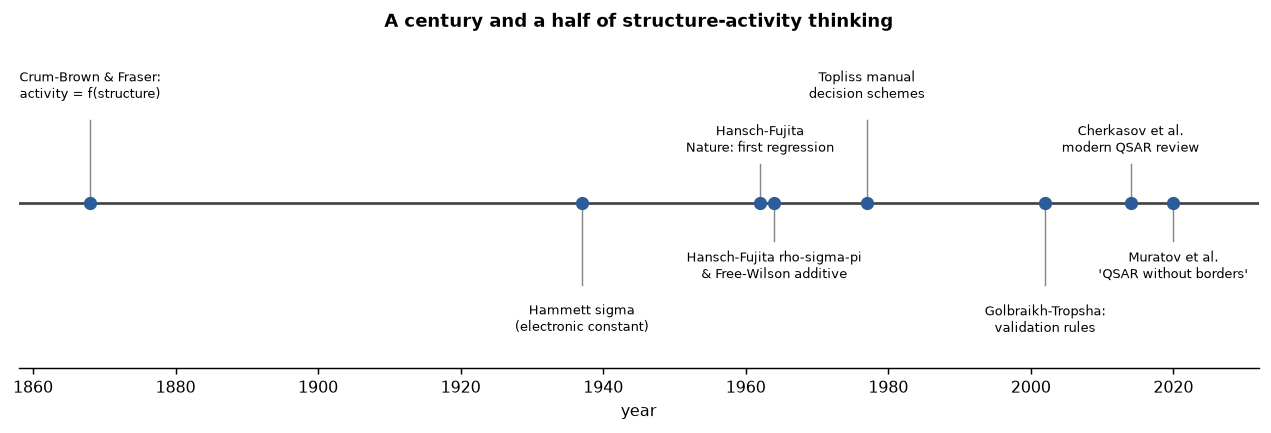

In [2]:
# A timeline of classical QSAR (drawn, not pasted). Code hidden in the HTML; it is here if you want it.
events = [(1868, "Crum-Brown & Fraser:\nactivity = f(structure)"),
          (1937, "Hammett sigma\n(electronic constant)"),
          (1962, "Hansch-Fujita\nNature: first regression"),
          (1964, "Hansch-Fujita rho-sigma-pi\n& Free-Wilson additive"),
          (1977, "Topliss manual\ndecision schemes"),
          (2002, "Golbraikh-Tropsha:\nvalidation rules"),
          (2014, "Cherkasov et al.\nmodern QSAR review"),
          (2020, "Muratov et al.\n'QSAR without borders'")]
fig, ax = plt.subplots(figsize=(10.0, 3.4))
ax.axhline(0, color="#444", lw=1.5, zorder=0)
levels = [1.4, -1.4, 0.65, -0.65, 1.4, -1.4, 0.65, -0.65]   # 4 staggered heights so neighbours never collide
for i, (yr, label) in enumerate(events):
    y = levels[i]
    ax.plot([yr, yr], [0, y*0.82], color="#888", lw=0.8)
    ax.scatter([yr], [0], s=40, color="#2b5d9b", zorder=3)
    ax.text(yr, y, label, ha="center", va="bottom" if y > 0 else "top", fontsize=7.0)
ax.set_ylim(-2.3, 2.3); ax.set_yticks([]); ax.set_xlim(1858, 2032)
ax.set_xlabel("year"); ax.set_title("A century and a half of structure-activity thinking")
for s in ["left", "right", "top"]: ax.spines[s].set_visible(False)
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The lineage of classical QSAR. The idea that activity is a function of structure predates structural chemistry (1868); Hammett (1937) and Hansch-Fujita (1962-64) made it quantitative; Free-Wilson (1964) gave the additive alternative; and a long modern literature (Topliss, Golbraikh-Tropsha, Cherkasov, Muratov) is concerned less with new mathematics than with <em>not fooling yourself</em> - the validation and interpretation problems that occupy the second half of this unit.</p>

<div class="box bridge"><h4>Chemistry box - Hammett &sigma; and hydrophobic &pi;, concretely</h4>
<p>These two constants are tabulated, one value per substituent, and were measured once and for all by physical-organic chemists. <strong>&sigma;</strong> (sigma) is read off benzoic-acid ionisation: it says how much a substituent pulls or pushes electron density. <strong>&pi;</strong> (pi) is read off octanol/water partitioning: it says how much more or less lipophilic (oil-loving, high logP) a substituent makes the molecule, relative to hydrogen. You do not compute them from the graph; you look them up. Modern QSAR mostly replaces them with graph-computed descriptors (logP, counts, fingerprints), but the interpretive habit - "this coefficient is the electronic effect, that one is the hydrophobic effect" - comes straight from Hansch.</p></div>

In [3]:
# Tabulated Hansch substituent constants (para position), from the physical-organic literature.
# sigma_p = Hammett electronic constant; pi = hydrophobic constant. One row per substituent.
subst = pd.DataFrame([
    ("-H",    0.00,  0.00), ("-CH3",  -0.17,  0.56), ("-OCH3", -0.27, -0.02),
    ("-OH",   -0.37, -0.67), ("-NH2",  -0.66, -1.23), ("-F",     0.06,  0.14),
    ("-Cl",    0.23,  0.71), ("-Br",    0.23,  0.86), ("-CF3",   0.54,  0.88),
    ("-CN",    0.66, -0.57), ("-NO2",   0.78, -0.28),
], columns=["substituent", "sigma_p (electronic)", "pi (hydrophobic)"])
print(subst.to_string(index=False))
print("\nElectron-withdrawing (sigma>0):", list(subst.loc[subst['sigma_p (electronic)']>0,'substituent']))
print("Makes molecule more lipophilic (pi>0):", list(subst.loc[subst['pi (hydrophobic)']>0,'substituent']))

substituent  sigma_p (electronic)  pi (hydrophobic)
         -H                  0.00              0.00
       -CH3                 -0.17              0.56
      -OCH3                 -0.27             -0.02
        -OH                 -0.37             -0.67
       -NH2                 -0.66             -1.23
         -F                  0.06              0.14
        -Cl                  0.23              0.71
        -Br                  0.23              0.86
       -CF3                  0.54              0.88
        -CN                  0.66             -0.57
       -NO2                  0.78             -0.28

Electron-withdrawing (sigma>0): ['-F', '-Cl', '-Br', '-CF3', '-CN', '-NO2']
Makes molecule more lipophilic (pi>0): ['-CH3', '-F', '-Cl', '-Br', '-CF3']


The table is the raw material of a 1964-style Hansch analysis: to model a series of para-substituted benzenes you would look up the $\sigma$ and $\pi$ of each substituent, stack them into a feature matrix, and regress the measured potencies on them. Notice the two columns are not redundant - nitro is strongly electron-withdrawing ($\sigma=0.78$) yet slightly hydrophilic ($\pi=-0.28$), while chloro is mildly electron-withdrawing and strongly lipophilic. A good descriptor set measures <em>distinct</em> things; when it does not, we get the collinearity trap of Section 7.

## 2. The QSAR workflow as a supervised-learning pipeline

Before any chemistry, fix the shape of the problem. A classical QSAR has five stages, and every one of them is a place where a chemical decision hides inside an apparently statistical step.

1. **Descriptors.** Turn each molecule into a fixed-length numeric vector $\mathbf{x}$. Here we use a handful of interpretable physicochemical descriptors from RDKit; Unit 5 used fingerprints, Unit 13 will compare them.
2. **Target.** Collect the measured endpoint $y$ - a (log-scaled) solubility or potency. Curation (Unit 7) decides which measurements are trustworthy enough to model.
3. **Split.** Separate the molecules into data the model may learn from and data kept hidden to test it. Doing this <em>honestly</em> for molecules is subtle enough to need its own unit (Unit 14).
4. **Fit.** Estimate the coefficients - for us, by ordinary least squares.
5. **Validate and interpret.** Measure predictivity on held-out molecules, and read the coefficients as chemistry.

The arrangement is exactly the supervised-regression loop you have met in any machine-learning course; the figure names the stages so the rest of the unit can refer to them.

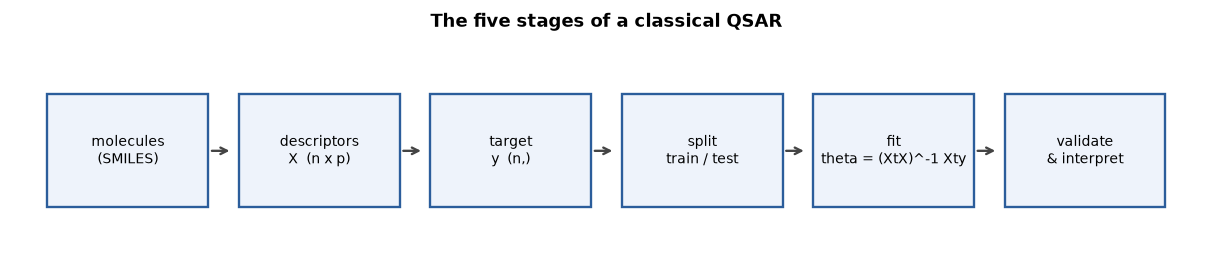

In [4]:
# The classical-QSAR pipeline as a labelled diagram (drawn with matplotlib; input hidden in HTML).
stages = ["molecules\n(SMILES)", "descriptors\nX  (n x p)", "target\ny  (n,)",
          "split\ntrain / test", "fit\ntheta = (XtX)^-1 Xty", "validate\n& interpret"]
fig, ax = plt.subplots(figsize=(9.4, 2.2))
x = np.arange(len(stages))
for i, s in enumerate(stages):
    ax.add_patch(plt.Rectangle((i-0.42, -0.5), 0.84, 1.0, fc="#eef3fb", ec="#2b5d9b", lw=1.3))
    ax.text(i, 0, s, ha="center", va="center", fontsize=8)
    if i < len(stages)-1:
        ax.annotate("", xy=(i+0.55, 0), xytext=(i+0.42, 0),
                    arrowprops=dict(arrowstyle="->", color="#444", lw=1.3))
ax.set_xlim(-0.6, len(stages)-0.4); ax.set_ylim(-1, 1); ax.axis("off")
ax.set_title("The five stages of a classical QSAR", fontsize=10, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> The classical-QSAR pipeline. Reading it left to right: structures become a descriptor matrix $X$ of shape $n\times p$ ($n$ molecules, $p$ descriptors) and a target vector $y$; the data is split; coefficients $\theta$ are fitted by the least-squares formula we derive in Section 4; and the model is validated and interpreted. Units 5-8 built the first two boxes; this unit lives in the last three. The warning carried through the unit is that stages 4 and 5 are easy and stages 3 and the honesty of 5 are hard.</p>

## 3. A descriptor matrix from RDKit

We need a real dataset with a measured property. We use the aqueous-solubility set of Delaney,<sup class="c"><a href="#r7">[7]</a></sup> a standard benchmark in which each compound carries a measured solubility.

<div class="box bridge"><h4>Chemistry box - aqueous solubility and logS</h4>
<p><strong>Solubility</strong> is how much of a compound will dissolve in water before the solution is saturated. It is one of the most consequential properties in drug discovery: a molecule that will not dissolve cannot be absorbed, however potent it is. It is reported as <strong>logS</strong>, the base-10 logarithm of the solubility expressed in moles per litre. A logS of 0 means 1&nbsp;mol/L (very soluble); logS = &minus;6 means a millionth of that (nearly insoluble). The scale is logarithmic for the same free-energy reason as pIC&#8325;&#8320;. Solubility is governed chiefly by how lipophilic the molecule is and by how much of it can hydrogen-bond to water - exactly the quantities our descriptors measure, which is why solubility is the classic interpretable QSAR (strictly, a QS<em>P</em>R, "property" rather than "activity", but the method is identical).</p></div>

The cell below bundles a curated 72-compound subset of Delaney's data directly in the notebook - name, canonical SMILES and measured logS - so the build is fully reproducible and needs no download. The subset was drawn to span the whole solubility range, from sugars and small alcohols at the soluble end to large polycyclic aromatics at the insoluble end. When you run the notebook in Colab you can replace this block with the full 1128-compound set (it is one CSV, fetched exactly as Units 6-7 fetch ChEMBL); the pipeline is unchanged.

In [5]:
# A curated 72-compound subset of Delaney's aqueous-solubility data, bundled for reproducibility.
# Format per line: name | canonical SMILES | measured logS (log10 mol/L).  Source: Delaney 2004 [7].
ESOL = """
Perylene|c1cc2cccc3c4cccc5cccc(c(c1)c23)c54|-8.80
Benzo(a)pyrene|c1ccc2c(c1)cc1ccc3cccc4ccc2c1c34|-8.70
Napthacene|c1ccc2cc3cc4ccccc4cc3cc2c1|-8.60
Etofenprox|CCOc1ccc(C(C)(C)COCc2cccc(Oc3ccccc3)c2)cc1|-8.60
2,2',4,4',5,5'-PCB|Clc1cc(Cl)c(-c2cc(Cl)c(Cl)cc2Cl)cc1Cl|-8.56
Benzo(k)fluoranthene|c1ccc2cc3c(cc2c1)-c1cccc2cccc-3c12|-8.49
1-Octadecanol|CCCCCCCCCCCCCCCCCCO|-8.40
Hexadecane|CCCCCCCCCCCCCCCC|-8.40
hexacosane|CCCCCCCCCCCCCCCCCCCCCCCCCC|-8.33
Tetradecane|CCCCCCCCCCCCCC|-7.96
Picene|c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21|-7.87
2,3',4,4'-PCB|Clc1ccc(-c2ccc(Cl)c(Cl)c2Cl)c(Cl)c1|-7.80
2,2',3,4,5,5'-PCB|Clc1ccc(Cl)c(-c2cc(Cl)c(Cl)c(Cl)c2Cl)c1|-7.68
2,3',4',5-PCB|Clc1ccc(Cl)c(-c2ccc(Cl)c(Cl)c2)c1|-7.25
2,2',3,4,5-PCB|Clc1cc(Cl)c(-c2cccc(Cl)c2Cl)cc1Cl|-7.21
7,12-Dimethylbenz(a)anthracene|Cc1c2ccccc2c(C)c2c1ccc1ccccc12|-7.02
Di(2-ethylhexyl)-phthalate|CCCCC(CC)COC(=O)c1ccccc1C(=O)OCC(CC)CCCC|-6.96
Methoxychlor|COc1ccc(C(c2ccc(OC)cc2)C(Cl)(Cl)Cl)cc1|-6.89
Pyrene|c1cc2ccc3cccc4ccc(c1)c2c34|-6.18
Pentylcyclopentane|CCCCCC1CCCC1|-6.08
Fluoranthene|c1ccc2c(c1)-c1cccc3cccc-2c13|-6.00
Nonane|CCCCCCCCC|-5.88
Trichloronate|CCOP(=S)(CC)Oc1cc(Cl)c(Cl)cc1Cl|-5.75
Carbophenthion|CCOP(=S)(OCC)SCSc1ccc(Cl)cc1|-5.74
Ronnel|COP(=S)(OC)Oc1cc(Cl)c(Cl)cc1Cl|-5.72
1,3,5-Tribromobenzene|Brc1cc(Br)cc(Br)c1|-5.60
1-Decene|C=CCCCCCCCC|-5.51
1-Methylfluorene|Cc1cccc2c1Cc1ccccc1-2|-5.22
2,6-PCB|Clc1cccc(Cl)c1-c1ccccc1|-5.21
3-Butanoyloxymethylphenytoin|CCCC(=O)OCN1C(=O)NC(c2ccccc2)(c2ccccc2)C1=O|-5.07
estriol|CC12CCC3c4ccc(O)cc4CCC3C1CC(O)C2O|-4.96
3-Chlorobiphenyl|Clc1cccc(-c2ccccc2)c1|-4.88
Mefenacet|CN(C(=O)COc1nc2ccccc2s1)c1ccccc1|-4.87
Niclosamide|O=C(Nc1ccc([N+](=O)[O-])cc1Cl)c1cc(Cl)ccc1O|-4.70
chloropropylate|CC(C)OC(=O)C(O)(c1ccc(Cl)cc1)c1cccc(Cl)c1|-4.53
Dicapthon|COP(=S)(OC)Oc1ccc([N+](=O)[O-])cc1Cl|-4.31
Triadimefon|CC(C)(C)C(=O)C(Oc1ccc(Cl)cc1)n1cncn1|-3.61
Ioxynil|N#Cc1cc(I)c(O)c(I)c1|-3.61
Propetamphos|CCNP(=S)(OC)OC(C)=CC(=O)OC(C)C|-3.41
Carbanilide|O=C(Nc1ccccc1)Nc1ccccc1|-3.15
Menadione|CC1=CC(=O)c2ccccc2C1=O|-3.03
3-Methyl-1-Butene|C=CC(C)C|-2.73
hydrochlorothiazide|NS(=O)(=O)c1cc2c(cc1Cl)NCNS2(=O)=O|-2.63
Pentachloroethane|ClC(Cl)C(Cl)(Cl)Cl|-2.60
5-hydroxyquinoline|Oc1cccc2ncccc12|-2.54
methylthiouracil|Cc1cc(=O)[nH]c(=S)[nH]1|-2.44
Benzylchloride|ClCc1ccccc1|-2.39
thioanisole|CSc1ccccc1|-2.39
Butabarbital|CCC(C)C1(CC)C(=O)NC(=O)NC1=O|-2.39
1-Napthol|Oc1cccc2ccccc12|-2.22
Methyl hexanoate|CCCCCC(=O)OC|-1.87
piperonal|O=Cc1ccc2c(c1)OCO2|-1.63
2,6-Dimethylphenol|Cc1cccc(C)c1O|-1.29
p-Methylaniline|Cc1ccc(N)cc1|-1.21
Malonic acid diethylester|CCOC(=O)CC(=O)OCC|-0.82
p-Aminophenol|Nc1ccc(O)cc1|-0.80
1-Nitropropane|CCC[N+](=O)[O-]|-0.80
4-Chlorophenol|Oc1ccc(Cl)cc1|-0.70
Dichloromethane|ClCCl|-0.63
Cyclohexanol|OC1CCCCC1|-0.44
Aniline|Nc1ccccc1|-0.41
Methyl propyl ether|CCCOC|-0.39
2-Pentanol|CCCC(C)O|-0.29
d-inositol|OC1C(O)C(O)C(O)C(O)C1O|0.35
2-Propanol|CC(C)O|0.43
2-Ethyl pyridine|CCc1ccccn1|0.51
1-Propanol|CCCO|0.62
Azodrin|CNC(=O)C=C(C)OP(=O)(OC)OC|0.65
4-hydroxypyridine|Oc1ccncc1|1.02
Ethanol|CCO|1.10
Pyridazine|c1ccnnc1|1.10
N,N-Dimethylacetamide|CC(=O)N(C)C|1.11
"""
rows = [ln.split("|") for ln in ESOL.strip().splitlines()]
df = pd.DataFrame(rows, columns=["name", "smiles", "logS"])
df["logS"] = df["logS"].astype(float)
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
assert df["mol"].notna().all(), "every SMILES must parse"
print(f"{len(df)} compounds | logS from {df.logS.min():.2f} (insoluble) to {df.logS.max():.2f} (soluble)")
print(df[["name", "smiles", "logS"]].head(4).to_string(index=False))

72 compounds | logS from -8.80 (insoluble) to 1.11 (soluble)
          name                                     smiles  logS
      Perylene         c1cc2cccc3c4cccc5cccc(c(c1)c23)c54  -8.8
Benzo(a)pyrene           c1ccc2c(c1)cc1ccc3cccc4ccc2c1c34  -8.7
    Napthacene                 c1ccc2cc3cc4ccccc4cc3cc2c1  -8.6
    Etofenprox CCOc1ccc(C(C)(C)COCc2cccc(Oc3ccccc3)c2)cc1  -8.6


Seventy-two molecules with a measured solubility spanning about ten log units - ten orders of magnitude in concentration. Before modelling, always <em>look</em> at the extremes: a QSAR that cannot tell these ends apart is worthless, and a QSAR that gets them right for the wrong reason is worse. The gallery shows the three most and three least soluble compounds in the set.

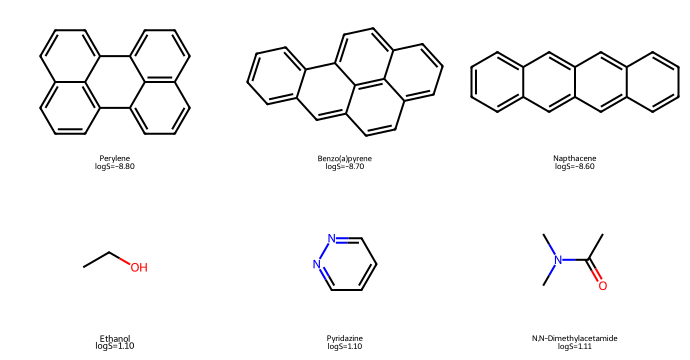

In [6]:
# Look at the chemistry: the three most and three least soluble compounds in the bundled set.
ds = df.sort_values("logS")
picks = pd.concat([ds.head(3), ds.tail(3)])
legends = [f"{n}\nlogS={v:.2f}" for n, v in zip(picks.name, picks.logS)]
Draw.MolsToGridImage(list(picks.mol), molsPerRow=3, subImgSize=(230, 180), legends=legends)

<p class="caption"><b>Figure 3.</b> The insoluble extreme (top row) and the soluble extreme (bottom row). The insoluble molecules are large, flat, carbon-rich polycyclic aromatics with no polar groups - nothing for water to hold on to; the soluble molecules are small and carry hydrogen-bonding oxygen or nitrogen. A chemist can predict the ranking by eye, which is the point: a good descriptor set must encode what the eye uses - size, lipophilicity, polar surface, aromaticity. The next cell computes exactly those.</p>

<div class="box bridge"><h4>Chemistry box - the descriptors we will use</h4>
<p>Five numbers, each computed from the molecular graph by RDKit, each with a plain meaning:
<strong>MolLogP</strong> - estimated octanol/water partition (lipophilicity, U1); higher = more oil-loving.
<strong>MolWt</strong> - molecular weight (size).
<strong>TPSA</strong> - topological polar surface area (U1), the summed surface of polar N/O atoms; a proxy for hydrogen-bonding capacity.
<strong>Aromatic proportion</strong> - fraction of heavy atoms that are aromatic; a proxy for flat, water-repelling ring surface.
<strong>Rotatable bonds</strong> - count of freely rotating single bonds; a proxy for flexibility.
These are the ingredients of Delaney's own ESOL equation and of countless solubility models.</p></div>

In [7]:
# Compute the five interpretable descriptors for every molecule -> the feature matrix X.
def descriptors(m):
    heavy = m.GetNumHeavyAtoms()
    aromatic = sum(1 for a in m.GetAtoms() if a.GetIsAromatic())
    return pd.Series({
        "MolLogP": Crippen.MolLogP(m),
        "MolWt":   Descriptors.MolWt(m),
        "TPSA":    Descriptors.TPSA(m),
        "AromProp": aromatic / heavy if heavy else 0.0,
        "RotB":    rdMolDescriptors.CalcNumRotatableBonds(m),
    })
feat_names = ["MolLogP", "MolWt", "TPSA", "AromProp", "RotB"]
D = df["mol"].apply(descriptors)
df = pd.concat([df, D], axis=1)
print(D.describe().round(2).to_string())

       MolLogP   MolWt    TPSA  AromProp   RotB
count    72.00   72.00   72.00     72.00  72.00
mean      3.24  210.47   24.93      0.47   2.71
std       2.42   99.69   28.66      0.38   4.29
min      -3.83   46.07    0.00      0.00   0.00
25%       1.30  125.99    0.00      0.00   0.00
50%       3.13  202.28   20.23      0.55   1.00
75%       5.25  297.68   41.46      0.75   4.00
max      10.39  390.56  121.38      1.00  23.00


<p class="caption"><b>Table.</b> Summary statistics of the five descriptors over the 72 compounds. Note the wildly different scales - logP runs from negative to about 8, while molecular weight is in the hundreds. That scale difference is harmless for prediction but makes raw coefficients incomparable, which is why Section 6 standardises them before interpreting their sizes. These are the columns of the matrix $X$; the measured logS is the vector $y$. We are ready to fit - but first, by hand.</p>

## 4. Worked example by hand: a two-descriptor model by the normal equations

A linear model predicts the target as a weighted sum of descriptors plus a constant:

<div class="eq">$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 .$$</div>

Least squares chooses the coefficients $\theta$ that minimise the sum of squared residuals $\sum_i (y_i - \hat{y}_i)^2$. Setting the derivatives to zero gives the **normal equations**, whose closed-form solution is the single most important formula in classical QSAR:

<div class="eq">$$\boxed{\;\hat{\theta} = (X^{\!\top} X)^{-1} X^{\!\top} y\;}$$
<span class="where">where $X$ is the design matrix (one row per molecule; columns are the descriptors, plus a column of ones for the intercept) and $y$ is the target vector. $X^{\!\top}X$ is a small $p\times p$ matrix - for two descriptors plus an intercept it is $3\times3$ - so the whole fit is a tiny linear solve.</span></div>

A $3\times3$ inverse is tedious to do on paper, but there is a standard trick that makes a two-descriptor fit genuinely hand-sized: **mean-centre** the data. If we subtract the mean from each descriptor and from the target, the intercept decouples (it becomes simply $\bar{y}$ minus the weighted means), and the two slopes come from a $2\times2$ system. We will trace it on a deliberately tiny, noise-free dataset so the arithmetic is clean, then confirm with code, then note why real data is never this kind.

<div class="box bridge"><h4>Chemistry box - the tiny dataset</h4>
<p>Five small molecules. Two descriptors a programmer can count by hand: $x_1 =$ number of carbon atoms (a crude size/lipophilicity proxy) and $x_2 =$ number of hydroxyl (&ndash;OH) groups (a crude hydrogen-bonding/solubility proxy). The response $y$ is a <em>contrived</em> solubility-like value, chosen so the model fits exactly - this section teaches the linear algebra, not the chemistry; the real, noisy solubility data returns in Section 5.</p></div>

The five molecules and their hand-countable descriptors:

<table class="mini"><tr><th>molecule</th><th>SMILES</th><th>$x_1$ = #C</th><th>$x_2$ = #OH</th><th>$y$ (contrived)</th></tr>
<tr><td>ethanol</td><td>CCO</td><td>2</td><td>1</td><td>2.0</td></tr>
<tr><td>propane</td><td>CCC</td><td>3</td><td>0</td><td>0.5</td></tr>
<tr><td>1,4-butanediol</td><td>OCCCCO</td><td>4</td><td>2</td><td>2.0</td></tr>
<tr><td>1-pentanol</td><td>CCCCCO</td><td>5</td><td>1</td><td>0.5</td></tr>
<tr><td>1-hexanol</td><td>CCCCCCO</td><td>6</td><td>1</td><td>0.0</td></tr></table>

**Step 1 - means.** $\bar{x}_1 = (2+3+4+5+6)/5 = 4$, $\bar{x}_2 = (1+0+2+1+1)/5 = 1$, $\bar{y} = (2+0.5+2+0.5+0)/5 = 1$.

**Step 2 - centre.** Subtract the means. The centred descriptors $x_1' , x_2'$ and target $y'$ are

$$x_1' = (-2,\,-1,\,0,\,1,\,2),\quad x_2' = (0,\,-1,\,1,\,0,\,0),\quad y' = (1,\,-0.5,\,1,\,-0.5,\,-1).$$

**Step 3 - build the $2\times2$ system** $X'^{\top}X'\,\theta = X'^{\top}y'$ from sums of products:

$$\textstyle\sum x_1'^2 = 4{+}1{+}0{+}1{+}4 = 10,\quad \sum x_2'^2 = 0{+}1{+}1{+}0{+}0 = 2,\quad \sum x_1'x_2' = 0{+}1{+}0{+}0{+}0 = 1,$$
$$\textstyle\sum x_1'y' = -2{+}0.5{+}0{-}0.5{-}2 = -4,\qquad \sum x_2'y' = 0{+}0.5{+}1{+}0{+}0 = 1.5 .$$

So we must solve
<div class="eq">$$\begin{pmatrix} 10 & 1 \\ 1 & 2 \end{pmatrix}\begin{pmatrix}\theta_1 \\ \theta_2\end{pmatrix} = \begin{pmatrix} -4 \\ 1.5 \end{pmatrix}.$$</div>

**Step 4 - solve the $2\times2$.** The determinant is $10\cdot2 - 1\cdot1 = 19$. By Cramer's rule,
$$\theta_1 = \frac{(-4)(2) - (1.5)(1)}{19} = \frac{-9.5}{19} = -0.5,\qquad \theta_2 = \frac{(10)(1.5) - (-4)(1)}{19} = \frac{19}{19} = +1.0 .$$

**Step 5 - recover the intercept.** $\theta_0 = \bar{y} - \theta_1\bar{x}_1 - \theta_2\bar{x}_2 = 1 - (-0.5)(4) - (1.0)(1) = 1 + 2 - 1 = 2.0 .$

So the hand-fitted model is $\hat{y} = 2.0 - 0.5\,x_1 + 1.0\,x_2$: each extra carbon lowers the response by half a unit (bigger, more lipophilic, less soluble) and each hydroxyl raises it by one (more hydrogen bonding, more soluble). The signs are the chemistry; the numbers are the arithmetic above. Now we confirm all of it in code.

In [8]:
# Confirm the hand fit three ways: counting descriptors with RDKit, the normal equations, and sklearn.
hand = [("ethanol","CCO",2.0),("propane","CCC",0.5),("1,4-butanediol","OCCCCO",2.0),
        ("1-pentanol","CCCCCO",0.5),("1-hexanol","CCCCCCO",0.0)]
oh = Chem.MolFromSmarts("[OX2H]")                       # a hydroxyl group
x1, x2, y = [], [], []
for name, smi, yi in hand:
    m = Chem.MolFromSmiles(smi)
    x1.append(sum(1 for a in m.GetAtoms() if a.GetSymbol() == "C"))   # count carbons
    x2.append(len(m.GetSubstructMatches(oh)))                          # count -OH groups
    y.append(yi)
x1, x2, y = np.array(x1, float), np.array(x2, float), np.array(y)
print("x1 (#C) =", x1.astype(int), " x2 (#OH) =", x2.astype(int), " y =", y)
print("means: x1bar=%.1f x2bar=%.1f ybar=%.1f" % (x1.mean(), x2.mean(), y.mean()))

x1 (#C) = [2 3 4 5 6]  x2 (#OH) = [1 0 2 1 1]  y = [2.  0.5 2.  0.5 0. ]
means: x1bar=4.0 x2bar=1.0 ybar=1.0


In [9]:
# (a) solve the centred 2x2 normal equations exactly as on paper
X1, X2, Y = x1 - x1.mean(), x2 - x2.mean(), y - y.mean()
A = np.array([[ (X1*X1).sum(), (X1*X2).sum() ],
              [ (X1*X2).sum(), (X2*X2).sum() ]])
b = np.array([ (X1*Y).sum(), (X2*Y).sum() ])
theta12 = np.linalg.solve(A, b)
theta0 = y.mean() - theta12 @ np.array([x1.mean(), x2.mean()])
print("normal equations:  A =", A.tolist(), " b =", b.tolist(), " det =", round(np.linalg.det(A), 1))
print("  theta1=%.4f  theta2=%.4f  theta0=%.4f" % (theta12[0], theta12[1], theta0))

# (b) the full formula theta = (X^T X)^-1 X^T y with an explicit intercept column
Xd = np.column_stack([np.ones_like(x1), x1, x2])
theta_full = np.linalg.inv(Xd.T @ Xd) @ Xd.T @ y
print("closed form (XtX)^-1 Xty:  theta0=%.4f theta1=%.4f theta2=%.4f" % tuple(theta_full))

# (c) scikit-learn
lr = LinearRegression().fit(np.column_stack([x1, x2]), y)
print("sklearn LinearRegression:  theta0=%.4f theta1=%.4f theta2=%.4f"
      % (lr.intercept_, lr.coef_[0], lr.coef_[1]))

normal equations:  A = [[10.0, 1.0], [1.0, 2.0]]  b = [-4.0, 1.5]  det = 19.0
  theta1=-0.5000  theta2=1.0000  theta0=2.0000
closed form (XtX)^-1 Xty:  theta0=2.0000 theta1=-0.5000 theta2=1.0000
sklearn LinearRegression:  theta0=2.0000 theta1=-0.5000 theta2=1.0000


All three routes return $\theta_0 = 2.0,\ \theta_1 = -0.5,\ \theta_2 = +1.0$ to machine precision, matching the hand derivation exactly, and the determinant of the centred system is 19 as computed on paper. Two lessons are worth stating. First, scikit-learn's <code>LinearRegression</code> is not magic: it is the boxed formula, and you have now executed that formula by three independent paths. Second, this dataset was <em>built</em> to fit perfectly (the residuals are zero), which never happens with measured data. Real solubility carries experimental noise and depends on more than two counts, so the next section's fit will leave residuals - and reading those residuals is where QSAR becomes a science rather than an exercise in linear algebra.

<div class="box warn"><h4>When the inverse does not exist</h4>
<p>The formula $(X^{\top}X)^{-1}$ fails if $X^{\top}X$ is singular - which happens exactly when two descriptors are perfectly correlated (one is a linear function of another). Then the determinant is zero and there is no unique solution. Real descriptors are rarely <em>perfectly</em> correlated, but they are often <em>nearly</em> so, which makes the inverse numerically explosive rather than impossible. That is the collinearity trap, and Section 7 shows it detonating.</p></div>

## 5. Fitting and reading a linear QSAR: lipophilicity governs solubility

We now fit the real data. Start with the single most important descriptor for solubility - lipophilicity, <code>MolLogP</code> - and nothing else. A one-descriptor model is the honest baseline every QSAR should beat before adding complexity.

In [10]:
# A one-descriptor QSAR: predict logS from logP alone.
X = df[feat_names].to_numpy(float)
yv = df["logS"].to_numpy(float)
XlogP = df[["MolLogP"]].to_numpy(float)
m1 = LinearRegression().fit(XlogP, yv)
pred1 = m1.predict(XlogP)
r2_1 = m1.score(XlogP, yv)
rmse_1 = np.sqrt(np.mean((yv - pred1) ** 2))
print("logS ~ %.3f * logP + %.3f" % (m1.coef_[0], m1.intercept_))
print("R2 = %.3f    RMSE = %.3f log units" % (r2_1, rmse_1))

logS ~ -1.167 * logP + -0.146
R2 = 0.820    RMSE = 1.310 log units


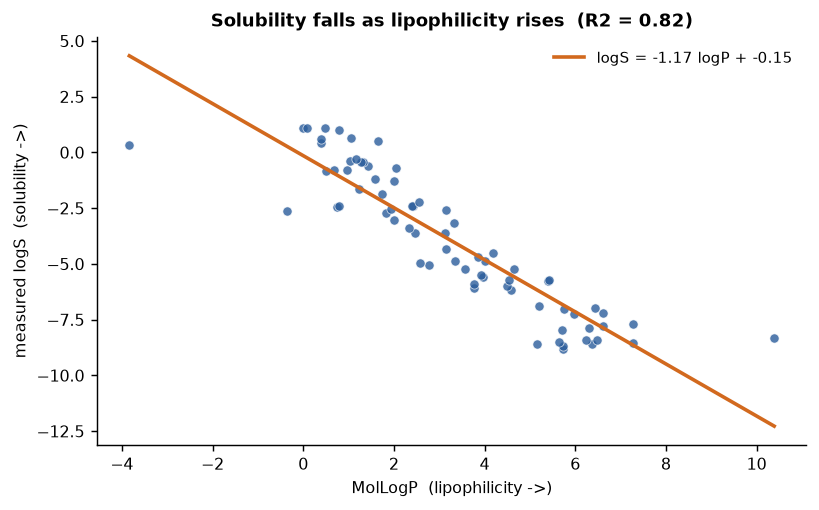

In [11]:
# Visualise the single-descriptor fit.
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.scatter(df["MolLogP"], yv, s=26, color="#2b5d9b", alpha=0.8, edgecolor="white", linewidth=0.4)
xs = np.linspace(df["MolLogP"].min(), df["MolLogP"].max(), 50)
ax.plot(xs, m1.predict(xs.reshape(-1, 1)), color="#d2691e", lw=2,
        label="logS = %.2f logP + %.2f" % (m1.coef_[0], m1.intercept_))
ax.set_xlabel("MolLogP  (lipophilicity ->)"); ax.set_ylabel("measured logS  (solubility ->)")
ax.set_title("Solubility falls as lipophilicity rises  (R2 = %.2f)" % r2_1)
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Aqueous solubility against estimated lipophilicity for the 72 compounds, with the least-squares line. A single descriptor already explains most of the variance (R&sup2; around 0.8). The slope is about &minus;1.2: <em>each unit of logP costs a bit more than one log unit of solubility.</em> That is a quantitative, falsifiable chemical statement - the first real QSAR of the course - and it matches the textbook intuition from Unit 1 that oil-loving molecules shun water. The scatter about the line is what the remaining descriptors and experimental noise must account for.</p>

<div class="box key"><h4>Key idea - a coefficient is a sentence</h4>
<p>The number &minus;1.2 is not decoration. It says: hold everything else fixed, make a molecule one logP unit more lipophilic, and its predicted log-solubility drops by 1.2 - a factor of ~16 in concentration. Reading coefficients as chemical sentences, and checking that the sentence is true and sensible, is the whole interpretive skill of classical QSAR. A model whose coefficients make no chemical sense is a bug, not a discovery.</p></div>

A regression line is best judged not on its own axes but on a **predicted-versus-observed** plot, where a perfect model lies on the diagonal. This is the standard QSAR diagnostic and we will use it for every model from here on.

five-descriptor fit: R2 = 0.852  RMSE = 1.190


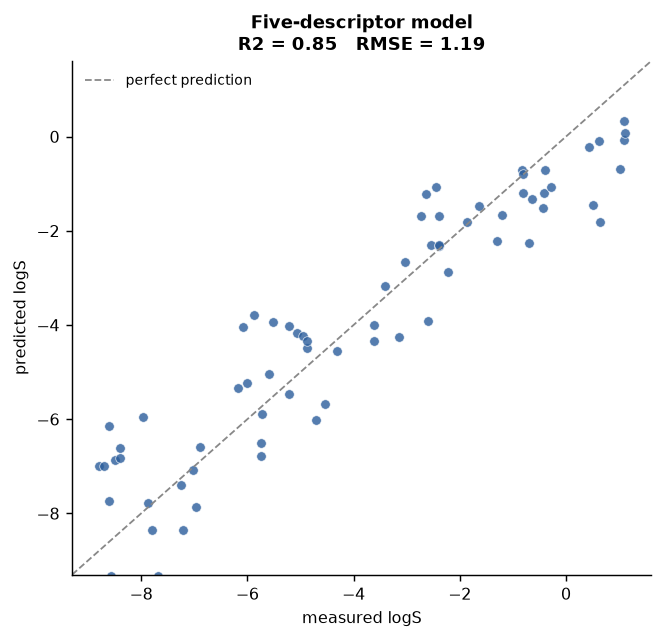

In [12]:
# Fit the full five-descriptor model and show predicted vs observed.
m5 = LinearRegression().fit(X, yv)
pred5 = m5.predict(X)
r2_5 = m5.score(X, yv)
rmse_5 = np.sqrt(np.mean((yv - pred5) ** 2))
fig, ax = plt.subplots(figsize=(5.2, 5.0))
lims = [yv.min() - 0.5, yv.max() + 0.5]
ax.plot(lims, lims, color="#888", ls="--", lw=1, label="perfect prediction")
ax.scatter(yv, pred5, s=28, color="#2b5d9b", alpha=0.8, edgecolor="white", linewidth=0.4)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("measured logS"); ax.set_ylabel("predicted logS")
ax.set_title("Five-descriptor model\nR2 = %.2f   RMSE = %.2f" % (r2_5, rmse_5))
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
print("five-descriptor fit: R2 = %.3f  RMSE = %.3f" % (r2_5, rmse_5))

<p class="caption"><b>Figure 5.</b> Predicted versus observed logS for the five-descriptor model. The points cluster around the diagonal with R&sup2; close to 0.85 - a visibly better fit than logP alone, with the largest errors at the insoluble extreme, where solubilities are hardest to measure and to model. But a higher R&sup2; on the data you fitted is <em>not</em> evidence of a better model: Sections 7 and 8 show that most of this gain is fragile, and that one of the four added descriptors is already lying to us about its chemistry.</p>

## 6. Reading the coefficients chemically - and a first warning

The five raw coefficients are not directly comparable because the descriptors have wildly different scales (logP in single digits, molecular weight in hundreds). The fix is the one from any statistics course: **standardise** each descriptor to zero mean and unit variance before fitting. The resulting *standardised coefficients* are all in the same units - log-solubility change per one-standard-deviation change in the descriptor - so their magnitudes rank the descriptors' influence.

In [13]:
# Standardised coefficients: fit on z-scored descriptors so magnitudes are comparable.
Xz = StandardScaler().fit_transform(X)
mz = LinearRegression().fit(Xz, yv)
coef = pd.DataFrame({"descriptor": feat_names,
                     "raw_coef": m5.coef_.round(4),
                     "std_coef": mz.coef_.round(3)})
coef["expected chemistry"] = ["lipophilicity opposes solubility",
                     "size opposes solubility",
                     "polar surface aids solubility",
                     "aromatic/flat surface opposes solubility",
                     "flexibility (minor)"]
print(coef.to_string(index=False))

descriptor  raw_coef  std_coef                       expected chemistry
   MolLogP   -1.2863    -3.085         lipophilicity opposes solubility
     MolWt   -0.0031    -0.306                  size opposes solubility
      TPSA   -0.0149    -0.425            polar surface aids solubility
  AromProp    0.3984     0.150 aromatic/flat surface opposes solubility
      RotB    0.1107     0.472                      flexibility (minor)


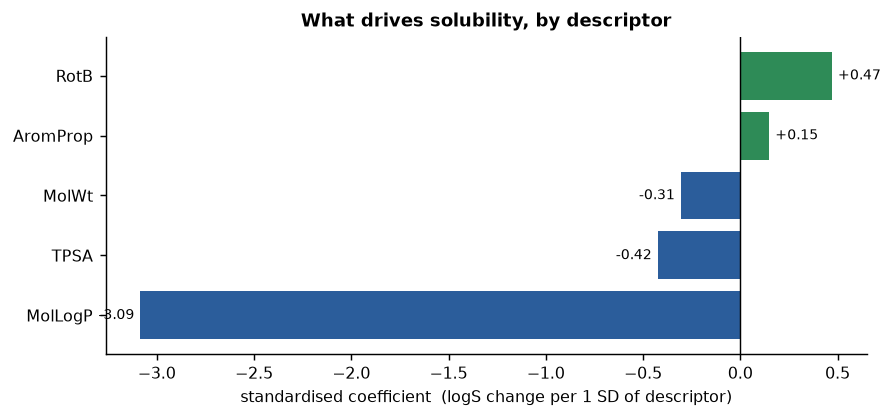

In [14]:
# Bar chart of standardised coefficients: sign and size of each descriptor's effect.
order = np.argsort(mz.coef_)
names_o = [feat_names[i] for i in order]
vals_o = mz.coef_[order]
colors = ["#2b5d9b" if v < 0 else "#2e8b57" for v in vals_o]
fig, ax = plt.subplots(figsize=(7.0, 3.3))
ax.barh(names_o, vals_o, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("standardised coefficient  (logS change per 1 SD of descriptor)")
ax.set_title("What drives solubility, by descriptor")
for y_, v in enumerate(vals_o):
    ax.text(v + (0.03 if v >= 0 else -0.03), y_, "%+.2f" % v,
            va="center", ha="left" if v >= 0 else "right", fontsize=8)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Standardised coefficients of the five-descriptor model. Lipophilicity (logP) dominates and is strongly negative - the chemistry of Section 5, now confirmed in the presence of the other descriptors. Molecular weight adds a further negative (bigger molecules are harder to dissolve). So far the signs are exactly what a chemist expects. <strong>But look at TPSA and aromatic proportion.</strong> Polar surface area should <em>help</em> solubility (polar atoms hydrogen-bond to water), yet its fitted coefficient is negative - the wrong sign, as if polar surface hurt solubility; and aromatic proportion, which should <em>hurt</em> solubility, comes out weakly positive - also backwards. The "expected chemistry" column of the table above states what each descriptor <em>should</em> do; two of the fitted signs contradict it. These are not chemical discoveries - they are the fingerprints of collinearity, which the next section exposes.</p>

<div class="box warn"><h4>Common misconception - "the sign tells me the mechanism"</h4>
<p>It is tempting to read every coefficient as a mechanism. But when descriptors are correlated, least squares <em>splits</em> a shared effect between them arbitrarily, and a coefficient can take a sign opposite to the descriptor's true physical effect. Here logP's <em>sign</em> (strongly negative) and its dominance are robust - every specification agrees lipophilicity governs solubility - but no descriptor in this set varies independently (the next section measures exactly how entangled each is), so the TPSA and aromatic terms have flipped to physically wrong signs and even logP's precise magnitude is uncertain. Never interpret a coefficient without checking the collinearity of its descriptor first.</p></div>

## 7. The collinearity trap

**Collinearity** (or multicollinearity) means two or more descriptors carry nearly the same information - they are strongly correlated across the dataset. For a computer scientist the cleanest way to see why it is fatal: if $x_a \approx x_b$, then the model $3x_a - 1x_b$, $2x_a + 0x_b$ and $-5x_a + 7x_b$ all make almost the same predictions, so least squares has no reason to prefer one, and tiny changes in the data swing the coefficients wildly between them. The predictions stay stable; the <em>coefficients</em>, which are what we wanted to interpret, become meaningless. Classical QSAR is especially prone to this because many molecular descriptors are different ways of measuring "how big and greasy is this molecule". We diagnose it in three escalating ways.

The first is simply the correlation matrix of the descriptors.

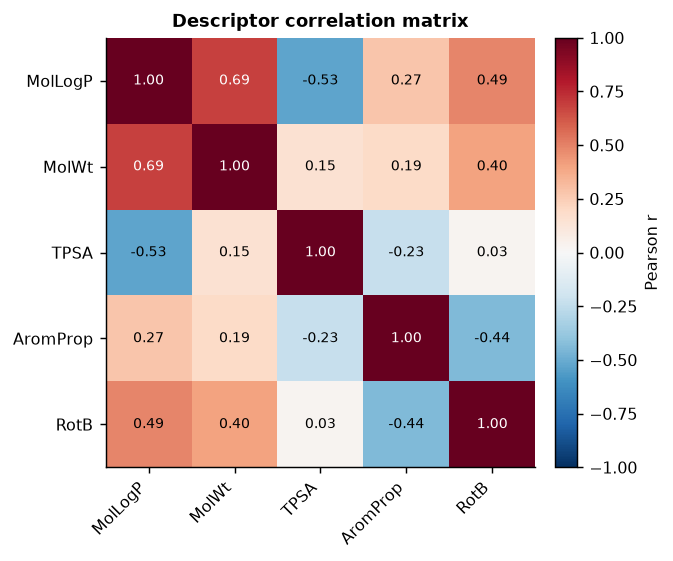

In [15]:
# Diagnosis 1: the descriptor-descriptor correlation matrix.
C = pd.DataFrame(X, columns=feat_names).corr()
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat_names))); ax.set_xticklabels(feat_names, rotation=45, ha="right")
ax.set_yticks(range(len(feat_names))); ax.set_yticklabels(feat_names)
for i in range(len(feat_names)):
    for j in range(len(feat_names)):
        ax.text(j, i, "%.2f" % C.iloc[i, j], ha="center", va="center", fontsize=8,
                color="white" if abs(C.iloc[i, j]) > 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
ax.set_title("Descriptor correlation matrix")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Correlations among the five descriptors. The off-diagonal that matters is logP with molecular weight (r around 0.7) and logP with TPSA (strongly negative) - lipophilicity, size and polar surface are not independent: large molecules tend to be more lipophilic, and polar surface is the opposite of lipophilicity almost by construction. These correlations are exactly why the TPSA and aromatic coefficients misbehaved in Figure 6. A rule of thumb flags |r| &gt; 0.7 as a collinearity concern, but pairwise correlation misses collinearity shared among three or more descriptors; for that we need the variance-inflation factor.</p>

The second diagnostic, the **variance-inflation factor (VIF)**, measures how much each descriptor can be predicted from *all* the others. Regress descriptor $j$ on the remaining descriptors, read off that regression's $R_j^2$, and compute $\mathrm{VIF}_j = 1/(1-R_j^2)$. A VIF of 1 means fully independent; conventional thresholds call VIF &gt; 5 troubling and VIF &gt; 10 serious.

In [16]:
# Diagnosis 2: variance-inflation factor for each descriptor.
def vif(Xmat, names):
    out = []
    for j in range(Xmat.shape[1]):
        others = np.delete(Xmat, j, axis=1)
        rj2 = LinearRegression().fit(others, Xmat[:, j]).score(others, Xmat[:, j])
        out.append(1.0 / (1.0 - rj2) if rj2 < 1 else np.inf)
    return pd.Series(out, index=names).round(2)
print("VIF (variance inflation factor):")
print(vif(X, feat_names).to_string())

VIF (variance inflation factor):
MolLogP     16.27
MolWt        7.67
TPSA         6.83
AromProp     2.24
RotB         3.72


The VIFs confirm and sharpen the picture: logP's VIF exceeds 10, past the "serious" threshold - it can be largely reconstructed from the other four descriptors - while molecular weight and TPSA sit in the troubling 5-to-8 band. This is the quantitative basis for the warning at the end of Section 6: logP's dominance and negative sign are robust (it is by far the strongest predictor however the model is specified), but its exact <em>magnitude</em>, and the signs of the descriptors entangled with it, are not to be trusted. The third diagnostic makes the danger visceral by deliberately adding a nearly-duplicate descriptor and watching the fit explode.

In [17]:
# Diagnosis 3: add a near-duplicate of logP (a copy plus a whisper of noise) and refit.
rng = np.random.default_rng(0)
logp = X[:, 0]
near = logp + rng.normal(0, 1e-3, size=logp.shape)         # 99.9999% identical to logP
Xdup = np.column_stack([logp, near])                        # two almost-identical columns
mdup = LinearRegression().fit(Xdup, yv)
print("correlation of the two columns: r = %.6f" % np.corrcoef(logp, near)[0, 1])
print("coefficient on logP copy #1: %+10.1f" % mdup.coef_[0])
print("coefficient on logP copy #2: %+10.1f" % mdup.coef_[1])
print("their sum:                   %+10.3f   (vs the honest single-logP slope %+.3f)"
      % (mdup.coef_[0] + mdup.coef_[1], m1.coef_[0]))
print("prediction R2 is unchanged:  %.3f" % mdup.score(Xdup, yv))

correlation of the two columns: r = 1.000000
coefficient on logP copy #1:      +69.9
coefficient on logP copy #2:      -71.1
their sum:                       -1.173   (vs the honest single-logP slope -1.167)
prediction R2 is unchanged:  0.821


This is the collinearity trap in its purest form. The two descriptors are identical to six decimal places, yet least squares hands one a large positive coefficient (here about +70) and the other a large negative one (about -71) - values that swing with the random seed and grow without bound as the noise shrinks - while <em>their sum</em> stays close to the honest single-logP slope and the prediction R&sup2; is unchanged. The model predicts fine and is interpretively worthless: nobody could read "logP helps solubility by +800 and hurts it by -800" as chemistry. Real descriptor sets contain softer versions of this all the time (molar refractivity vs weight, several size descriptors, counts that co-vary), which is why descriptor selection and de-correlation are part of building any classical QSAR.

<div class="box key"><h4>Key idea - remedies for collinearity</h4>
<ul>
<li><strong>Drop or merge</strong> redundant descriptors (keep one of each correlated group; this is what a careful Hansch analysis did by hand).</li>
<li><strong>Ridge regression</strong> adds a penalty $\lambda\sum\theta_j^2$ that shrinks coefficients toward zero and, crucially, <em>splits a shared effect evenly</em> instead of explosively - Hoerl and Kennard invented it for exactly this problem.<sup class="c"><a href="#r15">[15]</a></sup></li>
<li><strong>The lasso</strong> ($\lambda\sum|\theta_j|$) shrinks and <em>selects</em>, driving redundant coefficients exactly to zero.<sup class="c"><a href="#r16">[16]</a></sup></li>
<li><strong>Partial least squares (PLS)</strong> builds a few orthogonal components from the descriptors and is the traditional chemometrics answer to collinear descriptor blocks.<sup class="c"><a href="#r25">[25]</a></sup></li>
</ul></div>

at alpha=1e-4: coefs = [ 15.9 -17.1]
at alpha=10  : coefs = [-0.576 -0.577]


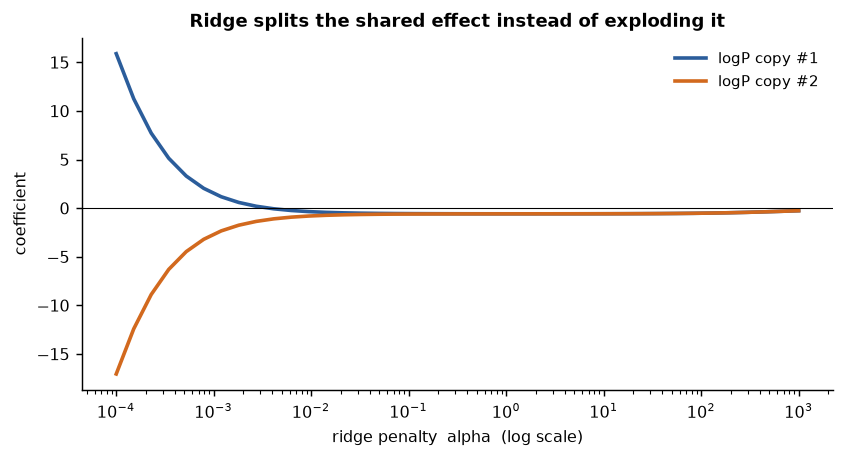

In [18]:
# Ridge tames the duplicate-descriptor explosion: sweep the penalty and watch the coefficients.
alphas = np.logspace(-4, 3, 40)
paths = np.array([Ridge(alpha=a).fit(Xdup, yv).coef_ for a in alphas])
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(alphas, paths[:, 0], color="#2b5d9b", lw=2, label="logP copy #1")
ax.plot(alphas, paths[:, 1], color="#d2691e", lw=2, label="logP copy #2")
ax.set_xscale("log"); ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("ridge penalty  alpha  (log scale)"); ax.set_ylabel("coefficient")
ax.set_title("Ridge splits the shared effect instead of exploding it")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()
print("at alpha=1e-4: coefs = %s" % np.round(paths[0], 1))
print("at alpha=10  : coefs = %s" % np.round(paths[np.argmin(np.abs(alphas-10))], 3))

<p class="caption"><b>Figure 8.</b> Ridge regression applied to the two near-duplicate logP columns, as the penalty $\alpha$ increases from left to right. At negligible penalty the two coefficients take the huge, opposite, unstable values of ordinary least squares; as the penalty grows they are pulled together and each settles near half of the true single-logP effect - the shared influence is now <em>split evenly and stably</em> rather than fought over. This is why regularised linear models are the default in modern QSAR even when the mathematics of the 1964 papers was pure least squares: the penalty buys interpretable, reproducible coefficients at a tiny cost in fit.</p>

## 8. Over-fitting: fit is not predictivity

The five-descriptor model's R&sup2; of about 0.85 (Figure 5) was measured on the very molecules it was fitted to. That number can be driven arbitrarily close to 1 simply by adding descriptors, whether or not they mean anything - a model with as many free parameters as data points fits perfectly and predicts nothing. The honest question is not "how well does it fit?" but "how well does it predict molecules it has not seen?". We answer it with **$k$-fold cross-validation**: split the data into $k$ parts, fit on $k-1$ and predict the held-out part, rotate, and report the pooled out-of-sample R&sup2; (often written $q^2$).

To dramatise over-fitting we add columns of pure random noise - standing in for the hundreds of meaningless descriptors a careless modeller might throw in - and watch the training R&sup2; climb while the cross-validated R&sup2; collapses.

In [19]:
# Over-fitting: add random 'descriptors' and compare training R2 with 5-fold cross-validated R2.
kf = KFold(n_splits=5, shuffle=True, random_state=0)
rng = np.random.default_rng(0)
extra_counts = [0, 2, 5, 10, 20, 40, 60]
train_r2, cv_r2 = [], []
for k in extra_counts:
    noise = rng.normal(size=(X.shape[0], k)) if k else np.empty((X.shape[0], 0))
    Xk = np.column_stack([X, noise])
    train_r2.append(LinearRegression().fit(Xk, yv).score(Xk, yv))
    cv_r2.append(cross_val_score(LinearRegression(), Xk, yv, cv=kf, scoring="r2").mean())
for k, tr, cv in zip(extra_counts, train_r2, cv_r2):
    print("5 real + %2d noise descriptors:  train R2 = %.3f   CV R2 = %+.3f" % (k, tr, cv))

5 real +  0 noise descriptors:  train R2 = 0.852   CV R2 = +0.750
5 real +  2 noise descriptors:  train R2 = 0.860   CV R2 = +0.757
5 real +  5 noise descriptors:  train R2 = 0.862   CV R2 = +0.753
5 real + 10 noise descriptors:  train R2 = 0.895   CV R2 = +0.777
5 real + 20 noise descriptors:  train R2 = 0.917   CV R2 = +0.670
5 real + 40 noise descriptors:  train R2 = 0.939   CV R2 = +0.065
5 real + 60 noise descriptors:  train R2 = 0.986   CV R2 = -0.421


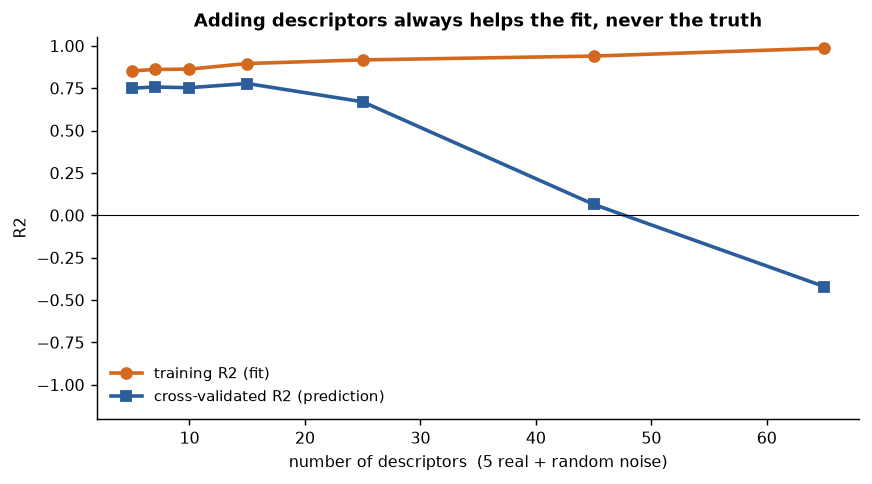

In [20]:
# The classic over-fitting figure: training fit rises, predictive skill falls.
fig, ax = plt.subplots(figsize=(6.8, 3.8))
tot = [5 + k for k in extra_counts]
ax.plot(tot, train_r2, "o-", color="#d2691e", lw=2, label="training R2 (fit)")
ax.plot(tot, cv_r2, "s-", color="#2b5d9b", lw=2, label="cross-validated R2 (prediction)")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("number of descriptors  (5 real + random noise)")
ax.set_ylabel("R2"); ax.set_ylim(-1.2, 1.05)
ax.set_title("Adding descriptors always helps the fit, never the truth")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The two curves tell opposite stories. The training R&sup2; (orange) rises monotonically toward 1 as noise descriptors are added - with enough columns the model memorises the 72 points perfectly. The cross-validated R&sup2; (blue) does the honest thing: it starts near the single-digit-descriptor value and then <em>falls</em>, going negative (worse than predicting the mean) once the descriptor count approaches the number of molecules. This is why the field's modern literature is obsessed with validation rather than fit: a published R&sup2; with no held-out test is uninformative at best.<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r14">[14]</a></sup></p>

<div class="box warn"><h4>Common misconception - "high R&sup2; means a good model"</h4>
<p>A high R&sup2; on the training data is necessary but nowhere near sufficient. Golbraikh and Tropsha's paper is titled, pointedly, "Beware of $q^2$!" - even a <em>cross-validated</em> score can mislead if the split is not chemically honest.<sup class="c"><a href="#r9">[9]</a></sup> Over-fitting was diagnosed for QSAR as early as the 1970s<sup class="c"><a href="#r23">[23]</a></sup> and its statistics laid out plainly by Hawkins.<sup class="c"><a href="#r28">[28]</a></sup> The reliable protocol - external test sets, applicability domain, scaffold- or time-based splits - is important enough that Unit 14 is devoted to it.</p></div>

<div class="box bridge"><h4>Bridge to Unit 14 - the applicability domain</h4>
<p>A QSAR is only trustworthy for molecules resembling those it was trained on - its <strong>applicability domain</strong>.<sup class="c"><a href="#r29">[29]</a></sup> Asking our solubility model about a metal complex or a protein would return a confident, meaningless number. Defining and enforcing that domain, and splitting data so the test set honestly represents future molecules, is the subject of Unit 14; here simply note that every coefficient and every R&sup2; in this unit is conditional on staying inside the chemical space of Figure 3.</p></div>

## 9. Free-Wilson analysis: activity as a sum of group contributions

The Hansch model of Sections 5-7 used <em>continuous physicochemical</em> descriptors. The Free-Wilson model of the same year takes the opposite tack: it uses only <strong>presence/absence indicators</strong> for the substituents in a congeneric series and lets least squares assign each substituent an additive **group contribution**.<sup class="c"><a href="#r2">[2]</a></sup> No physical constants are looked up; the contributions are read directly from the activity data.

<div class="box bridge"><h4>Chemistry box - a congeneric series and substitution positions</h4>
<p>A <strong>congeneric series</strong> is a family of molecules built on one fixed scaffold, differing only by which small groups (substituents) hang off a few defined positions. Think of the scaffold as a template with labelled slots R&sup1;, R&sup2;, ...; each molecule fills each slot with one substituent (H, CH&#8323;, Cl, ...). Free-Wilson assumes each substituent at each slot adds a fixed amount to the activity, independent of what sits in the other slots - the <em>additivity assumption</em>.</p></div>

Concretely, suppose a scaffold has two positions. Position R&sup1; can be H, CH&#8323; or Cl; position R&sup2; can be H or OH. The design matrix has one indicator column per non-reference substituent (we fold the reference choice H into the intercept), and the fitted intercept is the activity of the all-H parent. The cell builds a small illustrative series, fits it, and recovers the group contributions.

In [21]:
# Free-Wilson: an illustrative congeneric series with two substitution positions.
# True (hidden) additive contributions, to be recovered by least squares:
#   base(all-H) = 5.0 ;  R1: CH3 +0.8, Cl +1.5 (H = 0) ;  R2: OH -0.6 (H = 0)
series = pd.DataFrame([
    # R1 ,  R2 , measured activity (pIC50-like)
    ("H",   "H",  5.03), ("CH3", "H",  5.84), ("Cl",  "H",  6.47),
    ("H",   "OH", 4.38), ("CH3", "OH", 5.22), ("Cl",  "OH", 5.95),
    ("CH3", "H",  5.77), ("Cl",  "OH", 5.88), ("H",   "H",  4.95),
], columns=["R1", "R2", "activity"])
# one-hot encode with H as the EXPLICIT reference at each position (make H the first category,
# then drop_first drops it) -> the intercept is the all-H parent, coefficients are vs H.
for col in ["R1", "R2"]:
    cats = ["H"] + [c for c in series[col].unique() if c != "H"]
    series[col] = pd.Categorical(series[col], categories=cats)
D_fw = pd.get_dummies(series[["R1", "R2"]], drop_first=True).astype(float)
print("Free-Wilson design matrix (indicator columns):")
print(pd.concat([series[["R1", "R2"]], D_fw], axis=1).to_string(index=False))

Free-Wilson design matrix (indicator columns):
 R1 R2  R1_CH3  R1_Cl  R2_OH
  H  H     0.0    0.0    0.0
CH3  H     1.0    0.0    0.0
 Cl  H     0.0    1.0    0.0
  H OH     0.0    0.0    1.0
CH3 OH     1.0    0.0    1.0
 Cl OH     0.0    1.0    1.0
CH3  H     1.0    0.0    0.0
 Cl OH     0.0    1.0    1.0
  H  H     0.0    0.0    0.0


In [22]:
# Fit the additive model and read off each substituent's contribution.
fw = LinearRegression().fit(D_fw.to_numpy(), series["activity"].to_numpy())
contrib = pd.Series(fw.coef_, index=D_fw.columns)
contrib["(parent, all-H)"] = fw.intercept_
print(contrib.round(2).to_string())
print("\nR2 of the additive fit: %.3f" % fw.score(D_fw.to_numpy(), series["activity"].to_numpy()))

R1_CH3             0.82
R1_Cl              1.51
R2_OH             -0.58
(parent, all-H)    4.98

R2 of the additive fit: 0.997


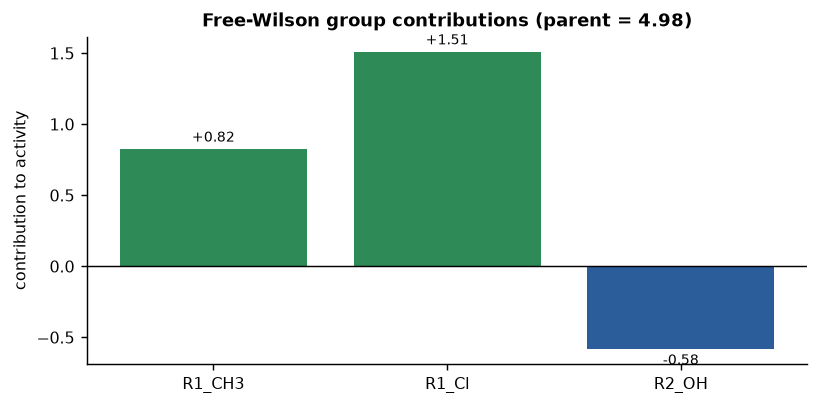

In [23]:
# Visualise the recovered group contributions.
c = contrib.drop("(parent, all-H)")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
cols = ["#2e8b57" if v > 0 else "#2b5d9b" for v in c.values]
ax.bar(range(len(c)), c.values, color=cols)
ax.set_xticks(range(len(c))); ax.set_xticklabels(c.index, rotation=0)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("contribution to activity")
ax.set_title("Free-Wilson group contributions (parent = %.2f)" % contrib["(parent, all-H)"])
for i, v in enumerate(c.values):
    ax.text(i, v + (0.03 if v >= 0 else -0.03), "%+.2f" % v,
            ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
fig.tight_layout()

<p class="caption"><b>Figure 10.</b> The group contributions recovered by least squares from the activity data alone. They match the hidden additive values that generated the series - chloro at R&sup1; contributes about +1.5 and methyl about +0.8 (both relative to H), while hydroxyl at R&sup2; contributes about -0.6, on top of an all-H parent near 5.0. This is the Free-Wilson promise: hand a chemist a table saying "swap H for Cl here and gain 1.5 log units", built directly from measured analogues with no physical theory. It is the discrete, additive cousin of the Hansch model's continuous slopes.</p>

<div class="box warn"><h4>The limits of additivity</h4>
<p>Free-Wilson has two built-in weaknesses, both consequences of its simplicity. First, it <strong>cannot predict a substituent it has never seen</strong> - there is no column for a group absent from the training analogues, whereas a Hansch model only needs that group's tabulated $\sigma$ and $\pi$. Second, it <strong>assumes the positions do not interact</strong>: if a chloro at R&sup1; only helps when R&sup2; is OH, the additive model cannot express it and the residuals absorb the discrepancy. The "two QSARs" are therefore complementary - Hansch generalises across chemical space through physical properties; Free-Wilson is sharply accurate within a known series but blind beyond it.<sup class="c"><a href="#r22">[22]</a></sup> Modern matched-molecular-pair analysis is a direct descendant of the Free-Wilson idea.</p></div>

## 10. Summary

You should now be able to explain, without notes:

- What QSAR is and where it came from: the structure-determines-property idea, Hammett's electronic constant $\sigma$, Hansch and Fujita's hydrophobic $\pi$ and the $\rho\sigma\pi$ regression,<sup class="c"><a href="#r8">[8]</a></sup> and Free-Wilson's additive alternative - the "two QSARs" still in use today, and the backbone of a large methodological literature.<sup class="c"><a href="#r3">[3]</a></sup><sup class="c"><a href="#r13">[13]</a></sup>
- That classical QSAR is supervised regression on molecular descriptors, and the five-stage pipeline descriptors &rarr; split &rarr; fit &rarr; validate &rarr; interpret.
- The least-squares normal equations $\hat{\theta}=(X^{\top}X)^{-1}X^{\top}y$, how mean-centring reduces a two-descriptor fit to a $2\times2$ solve, and that NumPy and scikit-learn simply execute this formula.
- How to build RDKit descriptors (logP,<sup class="c"><a href="#r11">[11]</a></sup> TPSA,<sup class="c"><a href="#r12">[12]</a></sup> weight, aromatic proportion, rotatable bonds<sup class="c"><a href="#r26">[26]</a></sup>) and fit a solubility QSAR, and how to read each coefficient as a chemical sentence (lipophilicity and size oppose solubility; polar surface aids it).
- Why a coefficient's sign can mislead: collinearity, diagnosed by correlation and variance-inflation factors, and demonstrated by the duplicate-descriptor explosion; and its remedies - dropping or merging descriptors, ridge regression, the lasso and PLS.<sup class="c"><a href="#r27">[27]</a></sup>
- The difference between fit and predictivity: cross-validation, the over-fitting curve, and why a training R&sup2; (or even a $q^2$) with no honest external test is uninformative.<sup class="c"><a href="#r10">[10]</a></sup><sup class="c"><a href="#r30">[30]</a></sup>
- How a Free-Wilson model recovers additive group contributions, and its additivity and extrapolation limits.

<div class="box key"><h4>The one thing to carry forward</h4>
<p>Classical QSAR is easy to fit and easy to fool. The mathematics is first-year linear algebra; the discipline is entirely in the chemistry - choosing descriptors that mean something, refusing to interpret coefficients that collinearity has scrambled, and never confusing a good fit with a good prediction. The common failure modes have been catalogued for decades, from Topliss and Costello's chance correlations<sup class="c"><a href="#r23">[23]</a></sup> to the "trouble with QSAR"<sup class="c"><a href="#r17">[17]</a></sup> and plainly worded guides on how <em>not</em> to build one.<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r24">[24]</a></sup> Unit 13 keeps the same pipeline but swaps linear regression for random forests, gradient boosting and support-vector machines;<sup class="c"><a href="#r20">[20]</a></sup> Unit 14 makes the validation honest.<sup class="c"><a href="#r18">[18]</a></sup> Everything you build there inherits the warnings of this unit, and rests on the open-source toolchain used throughout.<sup class="c"><a href="#r19">[19]</a></sup> The field's own retrospective - half a century on, still arguing about validation - is worth reading in full.<sup class="c"><a href="#r21">[21]</a></sup><sup class="c"><a href="#r31">[31]</a></sup></p></div>

## 11. Self-assessment

<details><summary>1. In one sentence, what is a classical QSAR to a programmer who knows regression?</summary>It is supervised regression in which the feature vector is a set of molecular descriptors (numbers computed from structure) and the target is a usually log-scaled measured property such as pIC&#8325;&#8320; or logS. Everything chemistry-specific is in the choice of descriptors, the interpretation of coefficients, and the ways molecular data breaks regression assumptions.</details>

<details><summary>2. Hansch and Free-Wilson both appeared in 1964. How do their feature sets differ?</summary>Hansch uses continuous physicochemical descriptors (hydrophobic &pi;, electronic &sigma;, steric terms, or modern computed descriptors like logP), so it can generalise to new substituents through their tabulated constants. Free-Wilson uses presence/absence indicator variables for each substituent at each position and fits an additive group contribution; it is accurate within a known series but cannot score a substituent it never saw.</details>

<details><summary>3. Why are potencies and solubilities almost always modelled on a logarithmic scale (pIC&#8325;&#8320;, logS)?</summary>Because the underlying quantity that is roughly additive in structural change is binding free energy, which is proportional to the logarithm of a concentration. The log scale also compresses values spanning many orders of magnitude into a range where least squares behaves well and errors are comparable across the range.</details>

<details><summary>4. Write the least-squares normal equations and explain why mean-centring helps a hand computation.</summary>$\hat{\theta}=(X^{\top}X)^{-1}X^{\top}y$. Mean-centring each descriptor and the target removes the intercept from the system: the slopes then come from a $p\times p$ system of the centred variables (for two descriptors, a $2\times2$ solve), and the intercept is recovered afterwards as $\bar{y}-\sum_j\theta_j\bar{x}_j$.</details>

<details><summary>5. In the hand example the centred normal-equation matrix had determinant 19. What would a determinant of 0 have meant?</summary>That the two centred descriptors were perfectly collinear (one an exact linear function of the other), making $X^{\top}X$ singular and the inverse non-existent - no unique least-squares solution. A near-zero determinant means near-collinearity: the inverse exists but is numerically explosive, so coefficients become huge and unstable.</details>

<details><summary>6. The logS-vs-logP slope was about -1.2. State the chemical claim this encodes and whether it is sensible.</summary>Making a molecule one logP unit more lipophilic lowers its predicted log-solubility by ~1.2 (about a 16-fold drop in molar solubility), all else equal. It is sensible: oil-loving molecules resist dissolving in water, exactly the "like dissolves like" principle from Unit 1.</details>

<details><summary>7. In the five-descriptor model, TPSA came out with a near-zero or wrong-signed coefficient even though polar surface should aid solubility. Why, and what should you do?</summary>TPSA is strongly (negatively) correlated with logP, so least squares splits the shared effect between them and can assign TPSA an uninterpretable coefficient. The fix is to recognise the collinearity (correlation matrix, VIF), and either drop/merge the redundant descriptor, regularise (ridge/lasso), or use PLS - not to report TPSA's raw coefficient as chemistry.</details>

<details><summary>8. Define the variance-inflation factor and give its rule-of-thumb thresholds.</summary>$\mathrm{VIF}_j = 1/(1-R_j^2)$, where $R_j^2$ is from regressing descriptor $j$ on all the others. VIF = 1 means fully independent; VIF &gt; 5 is a common warning threshold and VIF &gt; 10 signals serious collinearity that makes coefficient $j$ untrustworthy.</details>

<details><summary>9. When two descriptors were made near-identical, the two coefficients blew up to +/- hundreds while their sum stayed near the honest single-descriptor slope, and R&sup2; was unchanged. Explain.</summary>Collinearity leaves the predictions (which depend on the combined effect) well determined but the individual coefficients undetermined - infinitely many splits of the shared effect fit equally well, so least squares picks an extreme, noise-driven one. Prediction is fine; interpretation is destroyed. Regularisation (ridge) restores a stable, even split.</details>

<details><summary>10. As random noise descriptors were added, training R&sup2; rose toward 1 while cross-validated R&sup2; fell below 0. What is this called and what is the lesson?</summary>Over-fitting. Extra parameters let the model memorise the training points (fit improves) without capturing any real relationship (prediction worsens). The lesson: judge a model only by held-out prediction, and keep the number of descriptors well below the number of molecules.</details>

<details><summary>11. A colleague reports a solubility QSAR with training R&sup2; = 0.95 and no test set, and applies it to a metal-containing complex. Give two distinct objections.</summary>(i) A training-only R&sup2; is not evidence of predictivity - it can be inflated arbitrarily by adding descriptors; demand a cross-validated or external-test score. (ii) The metal complex is outside the model's applicability domain (nothing like it was in the training set, which was small organic molecules), so any prediction is extrapolation and untrustworthy regardless of R&sup2;.</details>

<details><summary>12. Free-Wilson gives a clean additive table of group contributions. Name one situation where additivity fails and what it implies.</summary>When substituent positions interact - e.g. a group at R&sup1; only boosts activity when a particular group sits at R&sup2; (non-additivity / an interaction term). The additive model cannot represent it; the interaction is dumped into the residuals, lowering the fit and, worse, giving misleading single-group contributions. It also fails for any substituent absent from the training analogues, which has no column at all.</details>

## Glossary

<dl class="gloss">
<dt>QSAR / QSPR</dt><dd>Quantitative structure-activity (or -property) relationship: a model predicting a measured activity or property from numeric descriptors of molecular structure.</dd>
<dt>Descriptor</dt><dd>Any number computed from a molecule's structure (molecular weight, logP, a ring count, a Hammett &sigma;, a fingerprint bit); the features of a QSAR.</dd>
<dt>Endpoint / activity</dt><dd>The measured property a QSAR predicts, e.g. pIC&#8325;&#8320; or logS.</dd>
<dt>Assay</dt><dd>A laboratory measurement of a molecule's biological effect.</dd>
<dt>IC&#8325;&#8320; / pIC&#8325;&#8320;</dt><dd>The concentration inhibiting a target by 50%, and its negative base-10 logarithm (in mol/L); pIC&#8325;&#8320; = 9 is one thousand times more potent than pIC&#8325;&#8320; = 6.</dd>
<dt>logS</dt><dd>Base-10 logarithm of aqueous solubility in mol/L; higher means more soluble.</dd>
<dt>Hammett constant (&sigma;)</dt><dd>A tabulated per-substituent number for electronic effect; positive = electron-withdrawing, negative = electron-donating.</dd>
<dt>Hydrophobic constant (&pi;)</dt><dd>A tabulated per-substituent number for how much it raises lipophilicity (logP) relative to hydrogen.</dd>
<dt>Hansch analysis</dt><dd>Classical QSAR using continuous physicochemical descriptors (&pi;, &sigma;, steric terms) in a linear regression.</dd>
<dt>Free-Wilson analysis</dt><dd>Classical QSAR using presence/absence indicators for substituents and fitting additive group contributions.</dd>
<dt>Congeneric series</dt><dd>A family of molecules sharing one scaffold and differing only in the substituents at defined positions.</dd>
<dt>Normal equations</dt><dd>The linear system $X^{\top}X\,\theta = X^{\top}y$ whose solution $\hat{\theta}=(X^{\top}X)^{-1}X^{\top}y$ minimises the least-squares error.</dd>
<dt>Standardised coefficient</dt><dd>A regression coefficient obtained after scaling each descriptor to unit variance, so coefficient magnitudes are comparable across descriptors.</dd>
<dt>Collinearity</dt><dd>Strong correlation among descriptors; leaves predictions stable but makes individual coefficients unstable and uninterpretable.</dd>
<dt>Variance-inflation factor (VIF)</dt><dd>$1/(1-R_j^2)$ from regressing descriptor $j$ on the others; quantifies how collinear descriptor $j$ is.</dd>
<dt>Ridge / lasso</dt><dd>Regressions that add an L2 ($\sum\theta^2$) or L1 ($\sum|\theta|$) penalty to shrink (ridge) or shrink-and-select (lasso) coefficients, taming collinearity.</dd>
<dt>Over-fitting</dt><dd>Fitting the training data (including its noise) so closely that predictivity on new data falls; signalled by training R&sup2; far above cross-validated R&sup2;.</dd>
<dt>Cross-validation / q&sup2;</dt><dd>Estimating out-of-sample performance by repeatedly fitting on part of the data and predicting the held-out part; the pooled out-of-sample R&sup2; is often called $q^2$.</dd>
<dt>Applicability domain</dt><dd>The region of chemical space where a model's predictions are trustworthy, roughly the neighbourhood of its training molecules.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Hansch C, Fujita T. &rho;-&sigma;-&pi; analysis. A method for the correlation of biological activity and chemical structure. <em>J Am Chem Soc</em>. 1964;86(8):1616&ndash;1626. <a href="https://doi.org/10.1021/ja01062a035">doi:10.1021/ja01062a035</a></li>
<li id="r2">Free SM, Wilson JW. A mathematical contribution to structure-activity studies. <em>J Med Chem</em>. 1964;7(4):395&ndash;399. <a href="https://doi.org/10.1021/jm00334a001">doi:10.1021/jm00334a001</a></li>
<li id="r3">Cherkasov A, Muratov EN, Fourches D, et al. QSAR modeling: where have you been? Where are you going to? <em>J Med Chem</em>. 2014;57(12):4977&ndash;5010. <a href="https://doi.org/10.1021/jm4004285">doi:10.1021/jm4004285</a></li>
<li id="r4">Dearden JC, Cronin MTD, Kaiser KLE. How not to develop a quantitative structure-activity or structure-property relationship (QSAR/QSPR). <em>SAR QSAR Environ Res</em>. 2009;20(3&ndash;4):241&ndash;266. <a href="https://doi.org/10.1080/10629360902949567">doi:10.1080/10629360902949567</a></li>
<li id="r5">Hammett LP. The effect of structure upon the reactions of organic compounds. Benzene derivatives. <em>J Am Chem Soc</em>. 1937;59(1):96&ndash;103. <a href="https://doi.org/10.1021/ja01280a022">doi:10.1021/ja01280a022</a></li>
<li id="r6">Hansch C, Maloney PP, Fujita T, Muir RM. Correlation of biological activity of phenoxyacetic acids with Hammett substituent constants and partition coefficients. <em>Nature</em>. 1962;194:178&ndash;180. <a href="https://doi.org/10.1038/194178b0">doi:10.1038/194178b0</a></li>
<li id="r7">Delaney JS. ESOL: estimating aqueous solubility directly from molecular structure. <em>J Chem Inf Comput Sci</em>. 2004;44(3):1000&ndash;1005. <a href="https://doi.org/10.1021/ci034243x">doi:10.1021/ci034243x</a></li>
<li id="r8">Hansch C. Quantitative approach to biochemical structure-activity relationships. <em>Acc Chem Res</em>. 1969;2(8):232&ndash;239. <a href="https://doi.org/10.1021/ar50020a002">doi:10.1021/ar50020a002</a></li>
<li id="r9">Golbraikh A, Tropsha A. Beware of q&sup2;! <em>J Mol Graph Model</em>. 2002;20(4):269&ndash;276. <a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r10">Gramatica P. Principles of QSAR models validation: internal and external. <em>QSAR Comb Sci</em>. 2007;26(5):694&ndash;701. <a href="https://doi.org/10.1002/qsar.200610151">doi:10.1002/qsar.200610151</a></li>
<li id="r11">Wildman SA, Crippen GM. Prediction of physicochemical parameters by atomic contributions. <em>J Chem Inf Comput Sci</em>. 1999;39(5):868&ndash;873. <a href="https://doi.org/10.1021/ci990307l">doi:10.1021/ci990307l</a></li>
<li id="r12">Ertl P, Rohde B, Selzer P. Fast calculation of molecular polar surface area as a sum of fragment-based contributions and its application to the prediction of drug transport properties. <em>J Med Chem</em>. 2000;43(20):3714&ndash;3717. <a href="https://doi.org/10.1021/jm000942e">doi:10.1021/jm000942e</a></li>
<li id="r13">Kubinyi H. QSAR and 3D QSAR in drug design. Part 1: methodology. <em>Drug Discov Today</em>. 1997;2(11):457&ndash;467. <a href="https://doi.org/10.1016/S1359-6446(97)01079-9">doi:10.1016/S1359-6446(97)01079-9</a></li>
<li id="r14">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6&ndash;7):476&ndash;488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r15">Hoerl AE, Kennard RW. Ridge regression: biased estimation for nonorthogonal problems. <em>Technometrics</em>. 1970;12(1):55&ndash;67. <a href="https://doi.org/10.1080/00401706.1970.10488634">doi:10.1080/00401706.1970.10488634</a></li>
<li id="r16">Tibshirani R. Regression shrinkage and selection via the lasso. <em>J R Stat Soc Series B</em>. 1996;58(1):267&ndash;288. <a href="https://doi.org/10.1111/j.2517-6161.1996.tb02080.x">doi:10.1111/j.2517-6161.1996.tb02080.x</a></li>
<li id="r17">Johnson SR. The trouble with QSAR (or how I learned to stop worrying and embrace fallacy). <em>J Chem Inf Model</em>. 2008;48(1):25&ndash;26. <a href="https://doi.org/10.1021/ci700332k">doi:10.1021/ci700332k</a></li>
<li id="r18">Dudek AZ, Arodz T, Galvez J. Computational methods in developing quantitative structure-activity relationships (QSAR): a review. <em>Comb Chem High Throughput Screen</em>. 2006;9(3):213&ndash;228. <a href="https://doi.org/10.2174/138620706776055539">doi:10.2174/138620706776055539</a></li>
<li id="r19">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software archive on Zenodo/DataCite; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r20">Mitchell JBO. Machine learning methods in chemoinformatics. <em>WIREs Comput Mol Sci</em>. 2014;4(5):468&ndash;481. <a href="https://doi.org/10.1002/wcms.1183">doi:10.1002/wcms.1183</a></li>
<li id="r21">Muratov EN, Bajorath J, Sheridan RP, et al. QSAR without borders. <em>Chem Soc Rev</em>. 2020;49(11):3525&ndash;3564. <a href="https://doi.org/10.1039/D0CS00098A">doi:10.1039/D0CS00098A</a></li>
<li id="r22">Fujita T, Winkler DA. Understanding the roles of the "two QSARs". <em>J Chem Inf Model</em>. 2016;56(2):269&ndash;274. <a href="https://doi.org/10.1021/acs.jcim.5b00229">doi:10.1021/acs.jcim.5b00229</a></li>
<li id="r23">Topliss JG, Costello RJ. Chance correlations in structure-activity studies using multiple regression analysis. <em>J Med Chem</em>. 1972;15(10):1066&ndash;1068. <a href="https://doi.org/10.1021/jm00280a017">doi:10.1021/jm00280a017</a></li>
<li id="r24">Topliss JG. A manual method for applying the Hansch approach to drug design. <em>J Med Chem</em>. 1977;20(4):463&ndash;469. <a href="https://doi.org/10.1021/jm00214a001">doi:10.1021/jm00214a001</a></li>
<li id="r25">Wold S, Sjostrom M, Eriksson L. PLS-regression: a basic tool of chemometrics. <em>Chemom Intell Lab Syst</em>. 2001;58(2):109&ndash;130. <a href="https://doi.org/10.1016/S0169-7439(01)00155-1">doi:10.1016/S0169-7439(01)00155-1</a></li>
<li id="r26">Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. Wiley-VCH; 2009. <a href="https://doi.org/10.1002/9783527628766">doi:10.1002/9783527628766</a></li>
<li id="r27">Cronin MTD, Schultz TW. Pitfalls in QSAR. <em>J Mol Struct THEOCHEM</em>. 2003;622(1&ndash;2):39&ndash;51. <a href="https://doi.org/10.1016/S0166-1280(02)00616-4">doi:10.1016/S0166-1280(02)00616-4</a></li>
<li id="r28">Hawkins DM. The problem of overfitting. <em>J Chem Inf Comput Sci</em>. 2004;44(1):1&ndash;12. <a href="https://doi.org/10.1021/ci0342472">doi:10.1021/ci0342472</a></li>
<li id="r29">Eriksson L, Jaworska J, Worth AP, Cronin MTD, McDowell RM, Gramatica P. Methods for reliability and uncertainty assessment and for applicability evaluations of classification- and regression-based QSARs. <em>Environ Health Perspect</em>. 2003;111(10):1361&ndash;1375. <a href="https://doi.org/10.1289/ehp.5758">doi:10.1289/ehp.5758</a></li>
<li id="r30">Consonni V, Ballabio D, Todeschini R. Comments on the definition of the Q&sup2; parameter for QSAR validation. <em>J Chem Inf Model</em>. 2009;49(7):1669&ndash;1678. <a href="https://doi.org/10.1021/ci900115y">doi:10.1021/ci900115y</a></li>
<li id="r31">Roy K, Kar S, Das RN. <em>Understanding the Basics of QSAR for Applications in Pharmaceutical Sciences and Risk Assessment</em>. Academic Press; 2015. <a href="https://doi.org/10.1016/C2014-0-00286-9">doi:10.1016/C2014-0-00286-9</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. &mdash; Chapter on QSAR and molecular descriptors.</li>
<li>Roy K, Kar S, Das RN. <em>Understanding the Basics of QSAR</em>. Academic Press; 2015. &mdash; A modern, practical QSAR textbook.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. &mdash; Linear regression, ridge, lasso and model validation at depth (free PDF).</li>
<li>Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. Wiley-VCH; 2009. &mdash; The encyclopaedic reference on descriptors.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>RDKit documentation &mdash; <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a> (the descriptor calculators used here).</li>
<li>scikit-learn user guide, linear models &mdash; <a href="https://scikit-learn.org/stable/modules/linear_model.html">scikit-learn.org</a>.</li>
<li>TeachOpenCADD talktorials (Volkamer Lab), ligand-based screening and ML &mdash; <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), including "QSAR in 8 lines of code" &mdash; <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>